In [43]:
import json
import numpy as np

In [44]:
with open(r"..\data\CUADv1.json") as file:
    dataset = json.load(file)

Explore Contract Lengths

In [45]:
data = dataset['data']

In [46]:
contract_lengths = [len(data[i]['paragraphs'][0]['context']) for i in range(len(data))]
contract_lengths = np.array(contract_lengths)

Text(0.5, 1.0, 'Frequency of Contract Lengths')

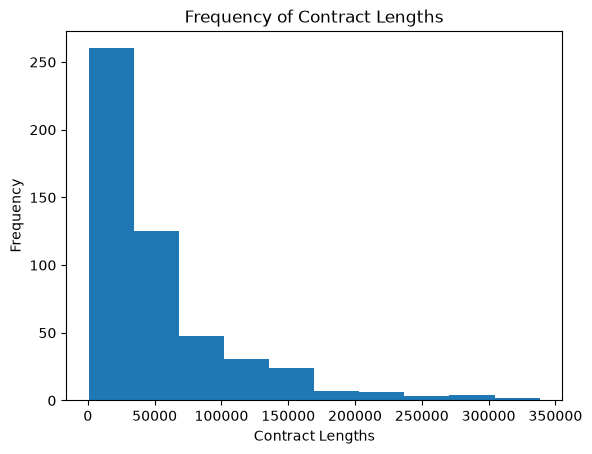

In [47]:
import matplotlib.pyplot as plt

plt.hist(contract_lengths)
plt.xlabel("Contract Lengths")
plt.ylabel("Frequency")
plt.title("Frequency of Contract Lengths")

In [48]:
avg_length = contract_lengths.mean()
max_length = contract_lengths.max()
min_length = contract_lengths.min()

print("Average Length: ", avg_length)
print("Max Length: ", max_length)
print("Min Length: ", min_length)

Average Length:  52563.00588235294
Max Length:  338211
Min Length:  645


Early transformer models can take a maximum of 512 tokens.

The minimum contract length already exceeds this limitation. This shows the importance of chunking.
```


```

Implement Basic Chunking

In [79]:
def chunk(chunk_length: int, overlap: int, text: list[str]) -> list[str]:
    tokens = text.split()

    chunks = []
    step_size = chunk_length - overlap
    for i in range(0, len(tokens), step_size):
        current_chunk = tokens[i:i+chunk_length]
        current_chunk = " ".join(current_chunk)
        chunks.append(current_chunk)

        if i + chunk_length >= len(tokens):
            break

    return chunks


In [90]:
text = "Here there this is bert reporting in, how is the chunking looking boss?"
chunk_length = 5
overlap = 4

chunks = chunk(chunk_length, overlap, text)
chunks

['Here there this is bert',
 'there this is bert reporting',
 'this is bert reporting in,',
 'is bert reporting in, how',
 'bert reporting in, how is',
 'reporting in, how is the',
 'in, how is the chunking',
 'how is the chunking looking',
 'is the chunking looking boss?']

In [91]:
print(f"Number of chunks: {len(chunks)}")

Number of chunks: 9


Chunk length and overlap determine the total # of chunks producded.

```

```

Chunk Quality Inspection

In [92]:
contract_1 = data[0]['paragraphs'][0]['context']
chunked_1 = chunk(128, 0, contract_1)
chunked_1[0]

'EXHIBIT 10.6 DISTRIBUTOR AGREEMENT THIS DISTRIBUTOR AGREEMENT (the "Agreement") is made by and between Electric City Corp., a Delaware corporation ("Company") and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999. RECITALS A. The Company\'s Business. The Company is presently engaged in the business of selling an energy efficiency device, which is referred to as an "Energy Saver" which may be improved or otherwise changed from its present composition (the "Products"). The Company may engage in the business of selling other products or other devices other than the Products, which will be considered Products if Distributor exercises its options pursuant to Section 7 hereof. B. Representations. As an inducement to the Company to enter into this Agreement, the Distributor has represented that it has or'

In [93]:
contract_2 = data[1]['paragraphs'][0]['context']
chunked_2 = chunk(100, 20, contract_2)
print(chunked_2[0])
print()
print(chunked_2[1])

Exhibit 10.26 CONFIDENTIAL TREATMENT HAS BEEN REQUESTED AS TO CERTAIN PORTIONS OF THIS DOCUMENT. EACH SUCH PORTION, WHICH HAS BEEN OMITTED HEREIN AND REPLACED WITH AN ASTERISK [*], HAS BEEN FILED SEPARATELY WITH THE SECURITIES AND EXCHANGE COMMISSION. PROMOTION AND DISTRIBUTION AGREEMENT This Promotion and Distribution Agreement including all exhibits (collectively referred to as the "Agreement"), effective as of 1 August 2011 (the "Effective Date"), is made by and between Whitesmoke Inc., with registered offices/principle place of business at 501 Silverside Road, Suite 105, Wilmington DE 19809, USA, ("Distributor"), and Google Inc whose principle place of business is at 1600

Silverside Road, Suite 105, Wilmington DE 19809, USA, ("Distributor"), and Google Inc whose principle place of business is at 1600 Amphitheatre Parkway, Mountain View, CA 94043, USA ("Google"). "Bundle" means the Distribution Products bundled with the Distributor App(s). "Chrome Browser" means the machine-readabl

We need to choose resonable numbers for chunk_length and overlap.

To do this, let's first explore the statistics of the label lengths
```

```

In [94]:
label_lengths = []
for contract in dataset['data']:
    for qa in contract['paragraphs'][0]['qas']:
        for answer in qa['answers']:
            label_lengths.append(len(answer['text'].split()))

Text(0.5, 1.0, 'Label Length Frequency')

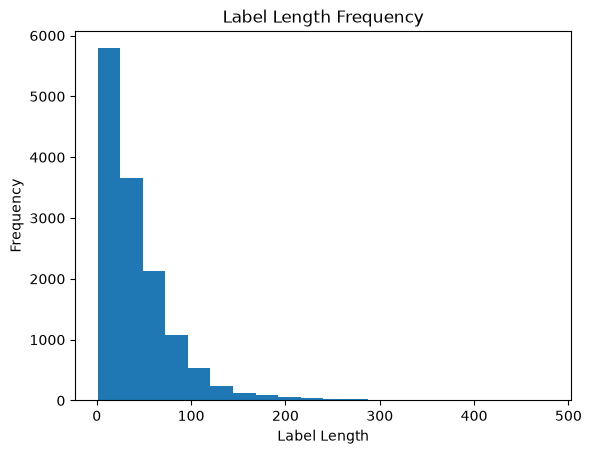

In [95]:
plt.hist(label_lengths, bins=20)
plt.xlabel("Label Length")
plt.ylabel("Frequency")
plt.title("Label Length Frequency")

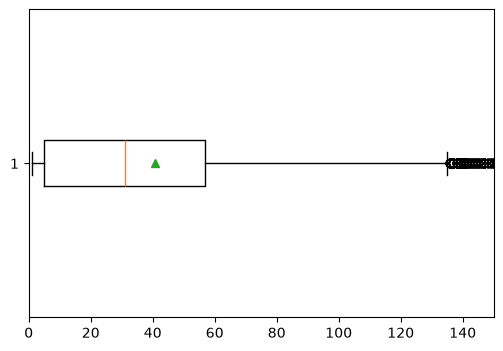

In [86]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(label_lengths, orientation='horizontal', showmeans=True)
ax.set_xlim(0, 150)
plt.show()

In [104]:
print(f"Median: {np.median(label_lengths)}")
print(f"Mean: {np.mean(label_lengths)}")
print(f"Q3: {np.percentile(label_lengths, 75)}")

print(f"{np.percentile(label_lengths, 90)}")

Median: 31.0
Mean: 40.678289806843665
Q3: 57.0
91.0


Since this will be a classification task, it would be in our interest to make chunks longer than they need to be. In the end, lawyers will have to read the chunks that have been classified as 'important' by our model. Longer chunk sizes would require laywers to spend more time reading unnecessary information before finding what they are actually looking for. 

That being said, too short of a chunk size would end up clipping our highlighted spans and could potentially negatively affect our model's performance.



90% of the label lengths are <= 91 tokens. We will choose a chunk size of **128** tokens, which would allow a single chunk to contain most of our highlighted span in its entirety, and a few extra tokens for safe measure.

We will also use an overlap of 15% (20 tokens), as a genereal recommendation for the size of our chunk.
```

```

In [105]:
chunk_length = 128
overlap = 20

contract_3 = data[2]['paragraphs'][0]['context']
chunked_3 = chunk(chunk_length, overlap, contract_3)

print(chunked_3[0])
print()
print(chunked_3[1])

Exhibit 10.16 SUPPLY CONTRACT Contract No: Date: The buyer/End-User: Shenzhen LOHAS Supply Chain Management Co., Ltd. ADD: Tel No. : Fax No. : The seller: ADD: The Contract is concluded and signed by the Buyer and Seller on , in Hong Kong. 1. General provisions 1.1 This is a framework agreement, the terms and conditions are applied to all purchase orders which signed by this agreement (hereinafter referred to as the "order"). 1.2 If the provisions of the agreement are inconsistent with the order, the order shall prevail. Not stated in order content will be subject to the provisions of agreement. Any modification, supplementary, give up should been written records, only to be valid by buyers and sellers authorized representative signature and confirmation, otherwise will be deemed invalid.

written records, only to be valid by buyers and sellers authorized representative signature and confirmation, otherwise will be deemed invalid. 2. The agreement and order 2.1 During the validity term

### Summary:

The contracts in our dataset are too long to be used as is. We will use chunking to split the contracts to smaller chunks that can be processed by the model. Chunk length and overlap are important parameters to be chosen and tuned.

Based on our perliminary statistics, we will use a 128 token chunk length and 20 token overlap to ensure most highlighted spans (>90%) can fit into a chunk. 

Chuking and overlap will be explored further in the next notebook when tokenizers are introduced.